# 02 — Data Preparation and Preprocessing

**Project:** Crop Yield Prediction and Forecasting Using Agricultural Data and Machine Learning

This notebook creates chronological partitions, sets up a straightforward **training-only** numerical/categorical preprocessor, and evaluates a simple reference baseline. It does **not** engineer features, select features using the target, or train advanced ML models.

The original CSV is preserved. Suspicious extreme values are **flagged** rather than automatically deleted; no historical source verification is available in this notebook.

## 1. Load the dataset

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Project directory
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

# Load dataset
csv_path = PROJECT_ROOT / "data" / "raw" / "crop_yield_dataset.csv"
if not csv_path.exists():
    raise FileNotFoundError(f"Missing source dataset: {csv_path}")
df = pd.read_csv(csv_path)

print(f"Dataset loaded: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Year range: {df['Year'].min()}–{df['Year'].max()}")


Dataset loaded: 198,369 rows x 15 columns
Year range: 1966–2017


## 2. Chronological training, validation and test partitions

We fit transformations only on records through 2011. Validation covers 2012–2014; 2015–2017 is reserved for final model evaluation.

In [2]:

# Split chronologically to avoid training on future records

train_df = df[df["Year"] <= 2011].copy()

val_df = df[
    (df["Year"] >= 2012) &
    (df["Year"] <= 2014)
].copy()

test_df = df[df["Year"] >= 2015].copy()

print("Training:", train_df.shape, "| Years:", train_df["Year"].min(), "-", train_df["Year"].max())
print("Validation:", val_df.shape, "| Years:", val_df["Year"].min(), "-", val_df["Year"].max())
print("Testing:", test_df.shape, "| Years:", test_df["Year"].min(), "-", test_df["Year"].max())

print("\nTotal records:", len(train_df) + len(val_df) + len(test_df))


Training: (176196, 15) | Years: 1966 - 2011
Validation: (11345, 15) | Years: 2012 - 2014
Testing: (10828, 15) | Years: 2015 - 2017

Total records: 198369


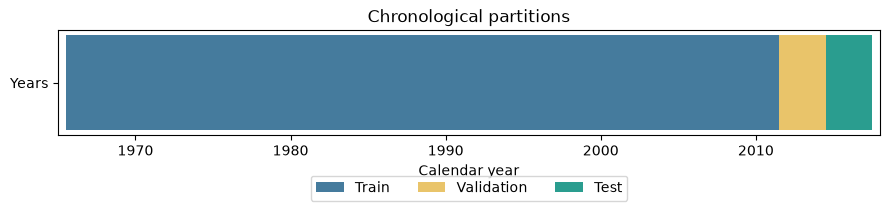

In [3]:
# Check that the three partitions are disjoint and complete
assert len(train_df) + len(val_df) + len(test_df) == len(df)
assert train_df["Year"].max() < val_df["Year"].min()
assert val_df["Year"].max() < test_df["Year"].min()
assert set(train_df.index).isdisjoint(val_df.index)
assert set(train_df.index).isdisjoint(test_df.index)
assert set(val_df.index).isdisjoint(test_df.index)

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.5))
for start, end, label, color in [(1966, 2011, "Train", "#457b9d"),
                                  (2012, 2014, "Validation", "#e9c46a"),
                                  (2015, 2017, "Test", "#2a9d8f")]:
    ax.barh("Years", end - start + 1, left=start - 0.5, label=label, color=color)
ax.set_xlim(1965, 2018)
ax.set_xlabel("Calendar year")
ax.set_title("Chronological partitions")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.32))
plt.tight_layout()
plt.show()

## 3. Outlier policy (no automatic deletion)

The previous data audit flagged unusually high Chickpea yields. They remain **suspected anomalies**, not verified errors. This notebook uses the original training rows as the no-treatment baseline, records the candidate rows for inspection, and leaves optional training-only exclusion for a dedicated, documented experiment. Validation and test rows are not filtered on `Yield`.

In [4]:
# Diagnostic flags only. Keep all rows by default.
chickpea_flags = train_df[(train_df["Crop"] == "Chickpea") & (train_df["Yield"] > 5000)]
print(f"Chickpea records above the exploratory 5,000 kg/ha threshold in training: {len(chickpea_flags)}")
display(chickpea_flags[["Year", "Region", "Crop", "Yield"]].sort_values("Yield", ascending=False).head(10))
print("Training rows retained:", len(train_df))

Chickpea records above the exploratory 5,000 kg/ha threshold in training: 2


,Year,Region,Crop,Yield
15772,2007,"Muzaffarpur, Bihar",Chickpea,58363.64
17654,2007,"Saharsa, Bihar",Chickpea,32000.00


Training rows retained: 176196


## 4. Predictor configuration and target

This is a **fixed research baseline**, not supervised feature selection. `Season` and total `Fertilizer` are excluded from the first configuration because of documented redundancy; `Pesticide` is excluded here because it is a national annual proxy. All columns remain in the original CSV, and alternative configurations may be compared in later experiments.

In [5]:

# Baseline feature selection
feature_cols = [
    "Year",
    "Region",
    "Crop",
    "Temperature",
    "Rainfall",
    "Humidity",
    "Soil Type",
    "pH",
    "Nitrogen",
    "Phosphorus",
    "Potassium"
]

target_col = "Yield"

# Separate predictors and target
X_train = train_df[feature_cols].copy()
y_train = train_df[target_col].copy()

X_val = val_df[feature_cols].copy()
y_val = val_df[target_col].copy()

X_test = test_df[feature_cols].copy()
y_test = test_df[target_col].copy()

print("Features:", len(feature_cols))
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)


Features: 11
Training: (176196, 11) (176196,)
Validation: (11345, 11) (11345,)
Testing: (10828, 11) (10828,)


## 5. Numerical scaling and categorical encoding

Numeric values are median-imputed and standardized; categorical values are imputed and one-hot encoded. `handle_unknown="ignore"` prevents errors at inference but does **not** mean a new district is supported; the app must validate geographic categories separately.

In [6]:

# Identify categorical and numerical features
categorical_cols = ["Region", "Crop", "Soil Type"]

numerical_cols = [
    col for col in feature_cols
    if col not in categorical_cols
]

# Preprocessing for numerical features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both transformations
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numerical_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

print("Numerical features:", numerical_cols)
print("Categorical features:", categorical_cols)


Numerical features: ['Year', 'Temperature', 'Rainfall', 'Humidity', 'pH', 'Nitrogen', 'Phosphorus', 'Potassium']
Categorical features: ['Region', 'Crop', 'Soil Type']


## 6. Fit on training data only

We fit the preprocessor using training records. Later periods are transformed without refitting. During model cross-validation, the whole preprocessor must be fitted inside each fold rather than reusing this fitted instance.

In [7]:

# Learn preprocessing parameters from training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations to validation data
X_val_processed = preprocessor.transform(X_val)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("Original validation shape:", X_val.shape)
print("Processed validation shape:", X_val_processed.shape)


Original training shape: (176196, 11)
Processed training shape: (176196, 344)
Original validation shape: (11345, 11)
Processed validation shape: (11345, 344)


In [8]:
# Verify encoded names and transformed matrix dimensions
feature_names = preprocessor.get_feature_names_out()
assert len(feature_names) == X_train_processed.shape[1]
assert X_val_processed.shape[1] == X_train_processed.shape[1]
print("Original predictors:", len(feature_cols))
print("Encoded predictors:", len(feature_names))
print("First transformed columns:")
display(pd.DataFrame({"Feature": feature_names}).head(20))

# Check that the encoder can transform an unseen categorical value
unseen_example = X_val.head(1).copy()
unseen_example["Region"] = "Unknown District, Unknown State"
assert preprocessor.transform(unseen_example).shape[1] == len(feature_names)
print("Unseen category transformation check passed (but unsupported regions need app validation).")

Original predictors: 11
Encoded predictors: 344
First transformed columns:


,Feature
0,numeric__Year
1,numeric__Temperature
2,numeric__Rainfall
3,numeric__Humidity
4,numeric__pH
5,numeric__Nitrogen
6,numeric__Phosphorus
7,numeric__Potassium
8,"categorical__Region_24 Parganas, West Bengal"
9,"categorical__Region_Adilabad, Telangana"


Unseen category transformation check passed (but unsupported regions need app validation).


## 7. Preprocessing verification

The transformed matrices should have the same width and contain only finite values. The target `Yield` stays in kg/ha; a log-target strategy is an independent modeling experiment, not a permanent alteration to the source data.

In [9]:

# Check the processed datasets
for name, X in [
    ("Training", X_train_processed),
    ("Validation", X_val_processed)
]:
    values = X.data if hasattr(X, "toarray") else X

    print(f"{name}:")
    print("Shape:", X.shape)
    print("Missing values:", np.isnan(values).sum())
    print("Infinite values:", np.isinf(values).sum())
    print()


Training:
Shape: (176196, 344)
Missing values: 0
Infinite values: 0

Validation:
Shape: (11345, 344)
Missing values: 0
Infinite values: 0



## 8. Simple validation baseline

A median `DummyRegressor` predicts the same training-period median for every record. This measures a minimal reference error, not crop-aware predictive skill. We do not evaluate the test period here.

In [10]:

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# Simple baseline: always predict the training median
dummy_model = DummyRegressor(strategy="median")

dummy_model.fit(X_train_processed, y_train)

# Predict validation yields
y_val_pred = dummy_model.predict(X_val_processed)

# Evaluate the predictions
mae = mean_absolute_error(y_val, y_val_pred)
rmse = root_mean_squared_error(y_val, y_val_pred)
r2 = r2_score(y_val, y_val_pred)

print("Dummy Regressor (Median Baseline)")
print(f"MAE:  {mae:.2f} kg/ha")
print(f"RMSE: {rmse:.2f} kg/ha")
print(f"R²:   {r2:.4f}")


Dummy Regressor (Median Baseline)
MAE:  1064.64 kg/ha
RMSE: 1930.89 kg/ha
R²:   -0.2533


## 9. Summary and next steps

- Chronological partitions are defined and validated.
- Raw observations are unchanged; suspicious Chickpea records are flagged, not automatically deleted.
- Numerical and categorical transformations are fit on training records only.
- Transformed feature names and shapes are checked.
- A simple median reference score is reported on validation data only.

**Not included:** feature engineering (new agricultural variables), supervised feature selection, advanced regression benchmarking, or final test evaluation. These remain independent research stages.

**Important downstream note:** This notebook does not overwrite existing `data/processed/train.csv`, `val.csv`, or `test.csv` because previously generated files may include engineered columns expected by later notebooks. Regenerate downstream artifacts deliberately after the research workflow is approved.